# Google Developer Group - Taif University (Task 1)

By : Saad Almalki / 0xSaad

### Importing libraries :

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [76]:
df1 = pd.read_csv("data/index1.csv")
df2 = pd.read_csv("data/index2.csv")

df1.columns = df1.columns.str.lower()

### Checking data :

In [77]:
df1.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


### Feature engineering

Combines `df1` and `df2` results in df

In [78]:
df = pd.concat([df1, df2], ignore_index=True)

Combines "Americano with milk" and "Americano with Milk" results

In [79]:
df.columns = df.columns.str.strip().str.lower()

df["coffee_name"] = df["coffee_name"].replace("Americano with milk", "Americano with Milk")

In [80]:
df["money"] = pd.to_numeric(df["money"], errors="coerce")


if "datetime" in df.columns:
    df["datetime"] = pd.to_datetime(
        
        df["datetime"], format="mixed", errors="coerce"
        
    )



else:
    df["datetime"] = pd.to_datetime(
        df["date"].astype(str) + " " + df["time"].astype(str),
        errors="coerce"
        
    )


df["hour"] = df["datetime"].dt.hour
df["weekday"] = df["datetime"].dt.day_name()
df["day"] = df["datetime"].dt.date
df["month"] = df["datetime"].dt.to_period("M")

In [81]:
display(df.head())

,date,datetime,cash_type,card,money,coffee_name,hour,weekday,day,month
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte,10,Friday,2024-03-01,2024-03
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate,12,Friday,2024-03-01,2024-03
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate,12,Friday,2024-03-01,2024-03
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano,13,Friday,2024-03-01,2024-03
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte,13,Friday,2024-03-01,2024-03


### Dataset overview  :


In [82]:
print("shape of dataset :", df.shape)
print("Total records : ", len(df))
print("Start date :", df["datetime"].min())
print("End date : ", df["datetime"].max())
print("Unique days : ", df["day"].nunique())

shape of dataset : (3898, 10)
Total records :  3898
Start date : 2024-03-01 10:15:50.520000
End date :  2025-03-23 21:23:11
Unique days :  381


### Data quality check :

In [83]:
df.info()

print("\n Missing Values:")
display(df.isna().sum())

print("\n Duplicated Rows:", df.duplicated().sum())
print("\n Money Data Type:", df["money"].dtype)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3898 entries, 0 to 3897
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3898 non-null   object        
 1   datetime     3898 non-null   datetime64[ns]
 2   cash_type    3898 non-null   object        
 3   card         3547 non-null   object        
 4   money        3898 non-null   float64       
 5   coffee_name  3898 non-null   object        
 6   hour         3898 non-null   int32         
 7   weekday      3898 non-null   object        
 8   day          3898 non-null   object        
 9   month        3898 non-null   period[M]     
dtypes: datetime64[ns](1), float64(1), int32(1), object(6), period[M](1)
memory usage: 289.4+ KB

 Missing Values:


date             0
datetime         0
cash_type        0
card           351
money            0
coffee_name      0
hour             0
weekday          0
day              0
month            0
dtype: int64


 Duplicated Rows: 2

 Money Data Type: float64


### Descriptive Statistics

In [84]:
print("Money Statistics:")
display(df["money"].describe().round(2))

print("\n")
print("Coffee sales :")
display(df["coffee_name"].value_counts())


print("\n")
print("Top 2 drinks :")
display(df["coffee_name"].value_counts().head(2))

Money Statistics:


count    3898.00
mean       31.38
std         5.06
min        15.00
25%        27.92
50%        32.82
75%        35.76
max        40.00
Name: money, dtype: float64



Coffee sales :


coffee_name
Americano with Milk           868
Latte                         806
Americano                     593
Cappuccino                    517
Cortado                       292
Hot Chocolate                 282
Cocoa                         243
Espresso                      152
Irish whiskey                  21
Coffee with Irish whiskey      16
Tea                            16
Irish whiskey with milk        15
Chocolate with milk            12
Double Irish whiskey           12
Caramel with Irish whiskey      8
Super chocolate                 6
Chocolate with coffee           5
Mochaccino                      5
Irish with chocolate            5
Caramel with chocolate          4
Vanilla with Irish whiskey      3
Caramel with milk               3
Double espresso with milk       2
Caramel coffee                  2
Double vanilla                  2
Double espresso                 1
Chocolate                       1
Coffee with chocolate           1
Vanilla coffee                  1
Do



Top 2 drinks :


coffee_name
Americano with Milk    868
Latte                  806
Name: count, dtype: int64

### visualizations :

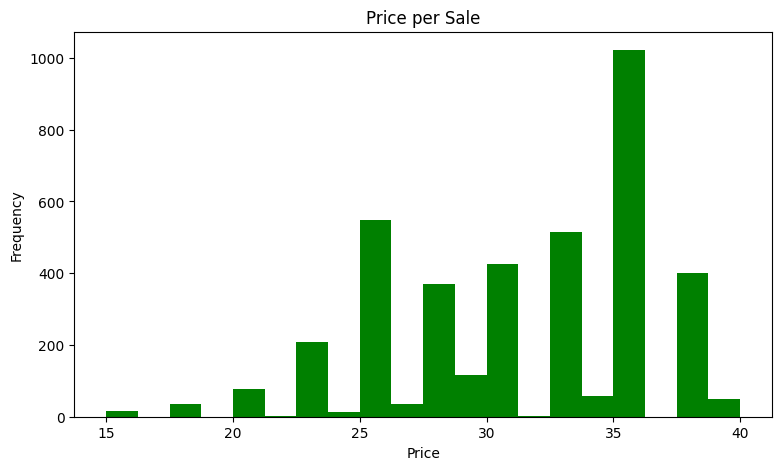

In [85]:
df["money"].plot(
    kind="hist",
    color="green",
    bins=20,
    figsize=(9, 5),
    title="Price per Sale"
)

plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

Text(0, 0.5, 'Coffee Name')

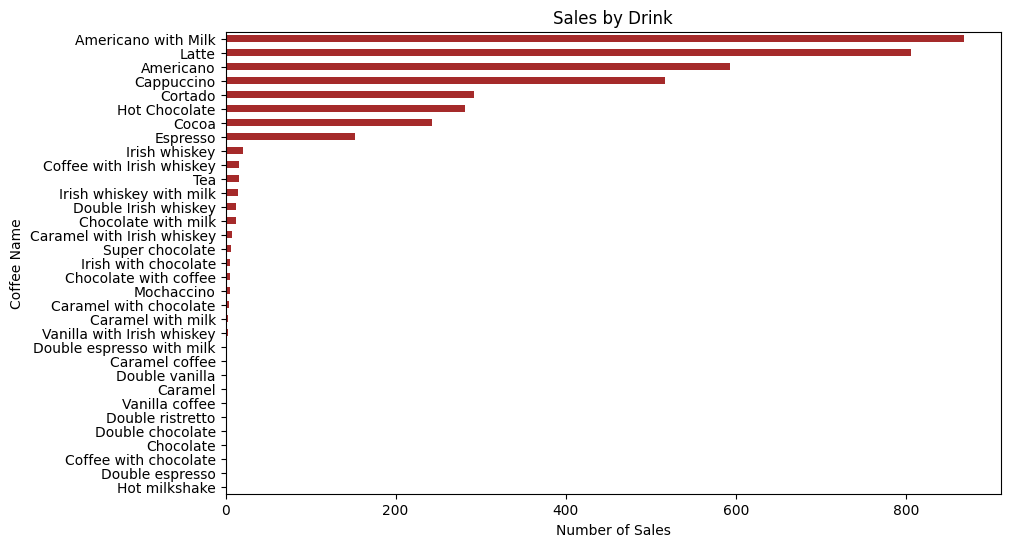

In [86]:
counts = df["coffee_name"].value_counts()

counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Sales by Drink",
    color="brown"
    
)

plt.xlabel("Number of Sales")
plt.ylabel("Coffee Name")


In [87]:
plt.show()

### Daily Performance Indicators

In [88]:
daily = df.groupby("day").agg(
    revenue=("money", "sum"),
    sales=("money", "count")
)

daily["avg_ticket"] = daily["revenue"] / daily["sales"]

display(daily.describe().round(2))

,revenue,sales,avg_ticket
count,381.00,381.00,381.00
mean,321.05,10.23,31.77
std,184.44,6.13,2.98
min,23.02,1.00,21.39
25%,190.54,6.00,29.79
50%,282.64,9.00,31.88
75%,403.64,13.00,33.92
max,979.08,35.00,39.35


### product performance :

In [89]:
prod = df.groupby("coffee_name").agg(
    sales=("money", "count"),
    revenue=("money", "sum"),
    avg_price=("money", "mean")
)

prod["share_%"] = prod["revenue"] / prod["revenue"].sum() * 100

display(prod.sort_values("revenue", ascending=False).round(1))

,sales,revenue,avg_price,share_%
coffee_name,,,,
Latte,806,28658.3,35.6,23.4
Americano with Milk,868,26369.1,30.4,21.6
Cappuccino,517,18514.1,35.8,15.1
Americano,593,15437.3,26.0,12.6
Hot Chocolate,282,10172.5,36.1,8.3
Cocoa,243,8678.2,35.7,7.1
Cortado,292,7534.9,25.8,6.2
Espresso,152,3187.3,21.0,2.6
Irish whiskey,21,525.0,25.0,0.4


### Sales analysis by hours :

In [90]:
by_hour = df.groupby("hour").agg(
    
    sales=("money", "count"),
    revenue=("money", "sum")
    
)

display(by_hour)


,sales,revenue
hour,,
6,5,149.40
7,99,3161.02
8,246,7329.88
9,258,7697.28
10,363,11357.52
11,316,9411.10
12,271,8190.62
13,241,7448.76
14,245,7705.80


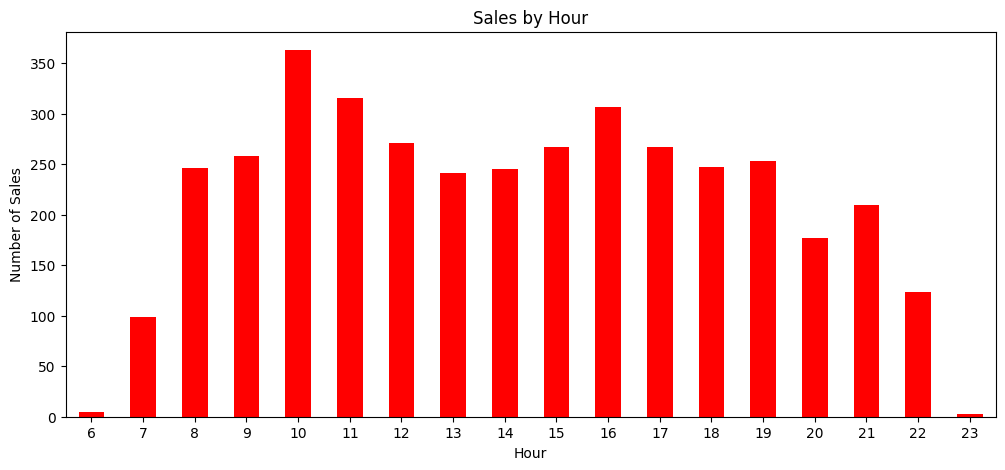

In [91]:
by_hour["sales"].plot(
    kind="bar",
    color="red",
    figsize=(12, 5),
    title="Sales by Hour"
)

plt.xlabel("Hour")
plt.ylabel("Number of Sales")
plt.xticks(rotation=0)

plt.show()

### Analysis within weeks

#### Days in week :

In [92]:
daysorder = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday
Monday       18714.10
Tuesday      19148.38
Wednesday    17182.46
Thursday     17025.40
Friday       18357.66
Saturday     16422.52
Sunday       15471.06
Name: money, dtype: float64

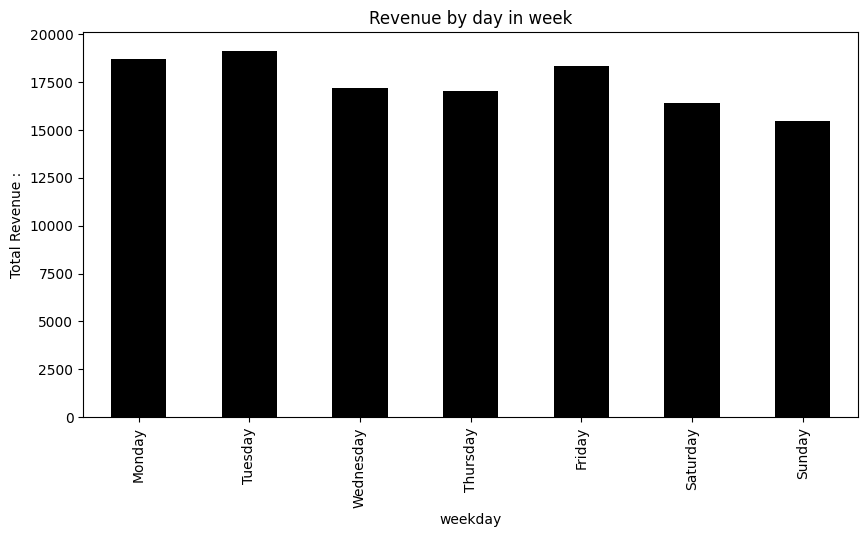

In [93]:
by_day = (
    df.groupby("weekday")["money"]
    .sum()
    .reindex(daysorder)
)

display(by_day.round(2))

by_day.plot(
    kind="bar",
    color="black",
    figsize=(10, 5),
    title="Revenue by day in week"
    
)

plt.ylabel("Total Revenue :")
plt.show()

### Sales analysis by months :

In [94]:
by_month = df.groupby("month")["money"].sum()

display(by_month.round(2))

month
2024-03     7050.20
2024-04     6720.56
2024-05     9063.42
2024-06     7758.76
2024-07     6915.94
2024-08     7613.84
2024-09     9988.64
2024-10    13891.16
2024-11     8590.54
2024-12     8237.74
2025-01     6398.86
2025-02    16804.48
2025-03    13287.44
Freq: M, Name: money, dtype: float64

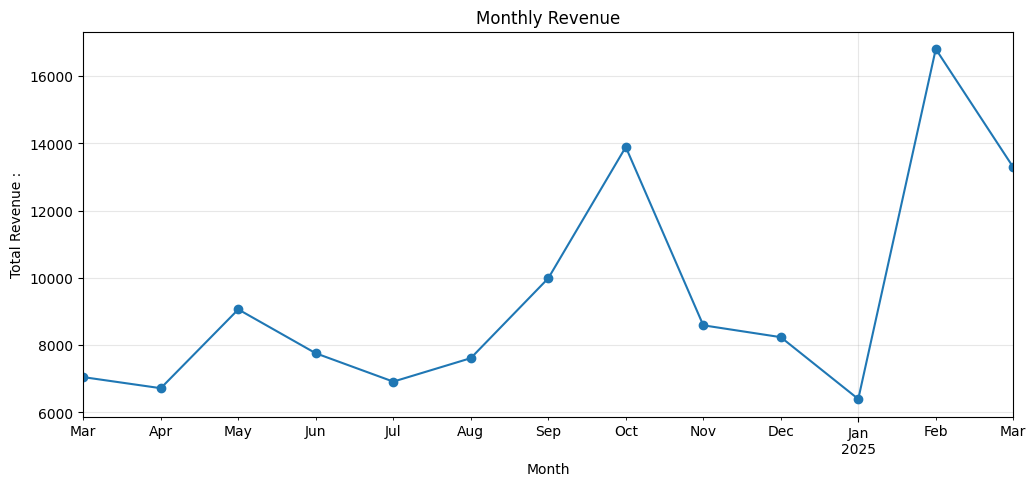

In [95]:
by_month.plot(
    kind="line",
    marker="o",
    figsize=(12, 5),
    title="Monthly Revenue"
)

plt.xlabel("Month")
plt.ylabel("Total Revenue :")
plt.grid(alpha=0.3)
plt.show()

#### Time periods in day

In [96]:
df["period"] = pd.cut(
    df["hour"],
    bins=[0, 12, 17, 24],
    labels=["Morning", "Afternoon", "Evening"],
    right=False
)

mix = pd.crosstab(
    df["coffee_name"],
    df["period"],
    normalize="columns"
) * 100

display(mix.round(2))

period,Morning,Afternoon,Evening
coffee_name,,,
Americano,18.03,18.33,9.14
Americano with Milk,27.20,19.46,20.23
Cappuccino,10.26,13.15,16.41
Caramel,0.00,0.00,0.08
Caramel coffee,0.00,0.08,0.08
Caramel with Irish whiskey,0.00,0.30,0.31
Caramel with chocolate,0.00,0.15,0.16
Caramel with milk,0.00,0.00,0.23
Chocolate,0.00,0.08,0.00


### Peak vs Quite times

In [97]:
busy_hour = by_hour["sales"].idxmax()
quiet_hour_raw = by_hour["sales"].idxmin()
top_drink = prod["revenue"].idxmax()

print("Busiest Hour:", busy_hour)
print("Quietest Hour (Overall):", quiet_hour_raw)
print("Top Revenue Drink:", top_drink)

Busiest Hour: 10
Quietest Hour (Overall): 23
Top Revenue Drink: Latte


In [99]:
ANALYST = "Saad Almalki / 0xSaad"
RECOMMENDATION = (
    "Test a Cocoa discount from 20:00 to 21:00, after confirming opening hours, "
    "because 20:00 has fewer sales than the nearby hours and Cocoa has evening demand. "
    "Compare sales, revenue and margin with similar days before the offer."
)

from datetime import date

print("=" * 55)
print("DECISION MEMO")
print("=" * 55)
print("Dataset  : Coffee Sales (Kaggle: ihelon/coffee-sales)")
print("Period   :", df["day"].min(), "->", df["day"].max())
print(f"Sales    : {len(df):,} | Revenue: {df['money'].sum():,.0f}")
print(f"Daily avg: {daily['revenue'].mean():,.1f}")
print(f"Peak hour: {busy_hour}:00 | Quiet hour (Overall): {quiet_hour_raw}:00")
print("Top drink:", top_drink)
print("-" * 55)
print("Recommendation:", RECOMMENDATION)
print("-" * 55)
print("Prepared by:", ANALYST, "| Data Scientist")
print("GDGoC Taif University |", date.today())
print("=" * 55)

DECISION MEMO
Dataset  : Coffee Sales (Kaggle: ihelon/coffee-sales)
Period   : 2024-03-01 -> 2025-03-23
Sales    : 3,898 | Revenue: 122,322
Daily avg: 321.1
Peak hour: 10:00 | Quiet hour (Overall): 23:00
Top drink: Latte
-------------------------------------------------------
Recommendation: Test a Cocoa discount from 20:00 to 21:00, after confirming opening hours, because 20:00 has fewer sales than the nearby hours and Cocoa has evening demand. Compare sales, revenue and margin with similar days before the offer.
-------------------------------------------------------
Prepared by: Saad Almalki / 0xSaad | Data Scientist
GDGoC Taif University | 2026-11-04
